# 🎄 Shapely Kütüphanesi Kapsamlı Eğitim Rehberi

**Santa 2025 - Noel Ağacı Paketleme Yarışması için Hazırlık**

Bu notebook şu konuları kapsar:
1. Temel Geometri Nesneleri (Point, LineString, Polygon)
2. Geometrik Dönüşümler (Translation, Rotation, Scaling)
3. Çarpışma Algılama (Collision Detection)
4. Uzamsal İlişkiler (intersects, touches, contains, within)
5. STRtree ile Hızlı Uzamsal Sorgular
6. Görselleştirme Teknikleri

## 📦 Gerekli Kütüphaneleri Yükleyelim

In [1]:
import shapely
from shapely import affinity
from shapely.geometry import Point, LineString, Polygon, MultiPolygon, box
from shapely.ops import unary_union
from shapely.strtree import STRtree
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
import numpy as np

print(f"Shapely Versiyonu: {shapely.__version__}")

Shapely Versiyonu: 2.1.2


---
## 1️⃣ Temel Geometri Nesneleri

Shapely'de üç temel geometri türü vardır:
- **Point** - Nokta
- **LineString** - Çizgi
- **Polygon** - Çokgen

### 1.1 Point (Nokta)

In [2]:
# Basit bir nokta oluşturma
nokta = Point(3, 5)
print(f"Nokta: {nokta}")
print(f"X koordinatı: {nokta.x}")
print(f"Y koordinatı: {nokta.y}")
print(f"Koordinatlar (tuple): {nokta.coords[:]}")

Nokta: POINT (3 5)
X koordinatı: 3.0
Y koordinatı: 5.0
Koordinatlar (tuple): [(3.0, 5.0)]


In [3]:
# İki nokta arası mesafe
nokta1 = Point(0, 0)
nokta2 = Point(3, 4)
mesafe = nokta1.distance(nokta2)
print(f"İki nokta arası mesafe: {mesafe}")

İki nokta arası mesafe: 5.0


### 1.2 LineString (Çizgi)

In [4]:
# Bir çizgi oluşturma
cizgi = LineString([(0, 0), (1, 1), (2, 0), (3, 1)])
print(f"Çizgi: {cizgi}")
print(f"Uzunluk: {cizgi.length:.4f}")
print(f"Sınır Kutusu (bounds): {cizgi.bounds}")

Çizgi: LINESTRING (0 0, 1 1, 2 0, 3 1)
Uzunluk: 4.2426
Sınır Kutusu (bounds): (0.0, 0.0, 3.0, 1.0)


### 1.3 Polygon (Çokgen) - 🌟 Yarışma için En Önemli!

In [29]:
# Basit bir dikdörtgen
dikdortgen = box(1, 0, 4, 3)  # minx, miny, maxx, maxy
print(f"Dikdörtgen: {dikdortgen}")
print(f"Alan: {dikdortgen.area}")
print(f"Çevre: {dikdortgen.length}")

Dikdörtgen: POLYGON ((4 0, 4 3, 1 3, 1 0, 4 0))
Alan: 9.0
Çevre: 12.0


In [6]:
# Manuel olarak çokgen oluşturma
ucgen = Polygon([(0, 0), (4, 0), (2, 3)])
print(f"Üçgen Alanı: {ucgen.area}")
print(f"Centroid (Ağırlık Merkezi): {ucgen.centroid}")

Üçgen Alanı: 6.0
Centroid (Ağırlık Merkezi): POINT (2 1)


In [7]:
# 🎄 Noel Ağacı benzeri karmaşık bir çokgen oluşturalım
# Bu yarışmada kullanılan ağaç şekline benzer

def noel_agaci_olustur(merkez_x=0, merkez_y=0, olcek=1.0):
    """
    Noel ağacı şeklinde bir çokgen oluşturur.
    Yarışmadaki ChristmasTree sınıfına benzer.
    """
    # Gövde boyutları
    govde_genislik = 0.15 * olcek
    govde_yukseklik = 0.2 * olcek
    
    # Ağaç katmanları
    taban_genislik = 0.7 * olcek
    orta_genislik = 0.4 * olcek
    ust_genislik = 0.25 * olcek
    
    # Y koordinatları
    tepe_y = 0.8 * olcek
    katman1_y = 0.5 * olcek
    katman2_y = 0.25 * olcek
    taban_y = 0.0
    govde_alt_y = -govde_yukseklik
    
    noktalar = [
        # Tepe
        (merkez_x, merkez_y + tepe_y),
        # Sağ üst katman
        (merkez_x + ust_genislik/2, merkez_y + katman1_y),
        (merkez_x + ust_genislik/4, merkez_y + katman1_y),
        # Sağ orta katman
        (merkez_x + orta_genislik/2, merkez_y + katman2_y),
        (merkez_x + orta_genislik/4, merkez_y + katman2_y),
        # Sağ taban
        (merkez_x + taban_genislik/2, merkez_y + taban_y),
        # Sağ gövde
        (merkez_x + govde_genislik/2, merkez_y + taban_y),
        (merkez_x + govde_genislik/2, merkez_y + govde_alt_y),
        # Sol gövde
        (merkez_x - govde_genislik/2, merkez_y + govde_alt_y),
        (merkez_x - govde_genislik/2, merkez_y + taban_y),
        # Sol taban
        (merkez_x - taban_genislik/2, merkez_y + taban_y),
        # Sol orta katman
        (merkez_x - orta_genislik/4, merkez_y + katman2_y),
        (merkez_x - orta_genislik/2, merkez_y + katman2_y),
        # Sol üst katman
        (merkez_x - ust_genislik/4, merkez_y + katman1_y),
        (merkez_x - ust_genislik/2, merkez_y + katman1_y),
    ]
    
    return Polygon(noktalar)

agac = noel_agaci_olustur(0, 0, 1.0)
print(f"Noel Ağacı Alanı: {agac.area:.4f}")
print(f"Sınır Kutusu: {agac.bounds}")

Noel Ağacı Alanı: 0.2456
Sınır Kutusu: (-0.35, -0.2, 0.35, 0.8)


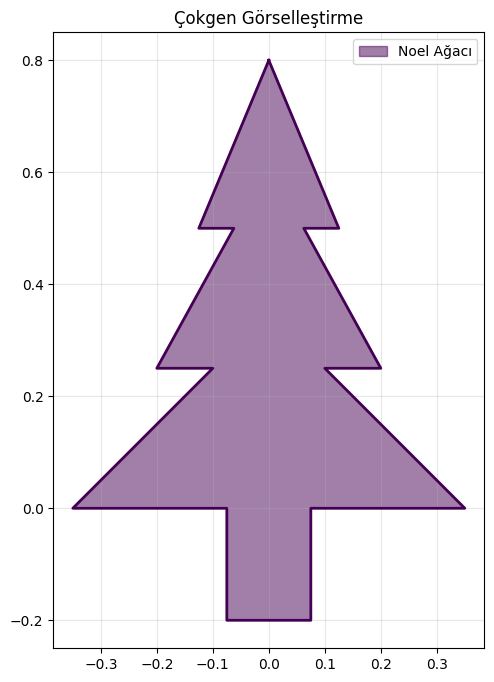

In [8]:
# Görselleştirme fonksiyonu
def cokgen_ciz(geometriler, basliklar=None, renkler=None, figsize=(8, 8)):
    """
    Birden fazla çokgeni görselleştirir.
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    if renkler is None:
        renkler = plt.cm.viridis(np.linspace(0, 1, len(geometriler)))
    
    for i, geo in enumerate(geometriler):
        x, y = geo.exterior.xy
        ax.fill(x, y, alpha=0.5, color=renkler[i])
        ax.plot(x, y, color=renkler[i], linewidth=2)
    
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    if basliklar:
        ax.legend(basliklar)
    plt.title("Çokgen Görselleştirme")
    plt.show()

# Ağacı çizelim
cokgen_ciz([agac], ['Noel Ağacı'])

---
## 2️⃣ Geometrik Dönüşümler (Affine Transformations)

Yarışmada ağaçları konumlandırmak ve döndürmek için kritik öneme sahip!

### 2.1 Translate (Öteleme)

Orijinal Centroid: POINT (1.1770812390003781e-18 0.2203986429177269)
Ötelenmiş Centroid: POINT (1.9999999999999998 1.220398642917727)


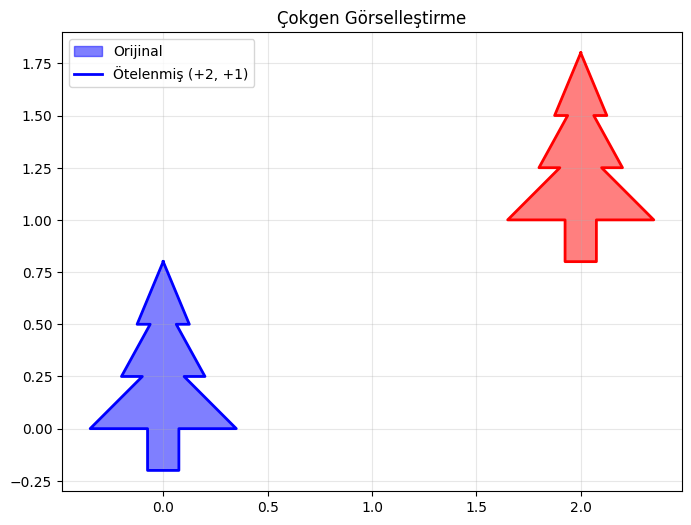

In [9]:
# Orijinal ağaç
orijinal_agac = noel_agaci_olustur(0, 0)

# X yönünde 2, Y yönünde 1 birim öteleme
otelenmis_agac = affinity.translate(orijinal_agac, xoff=2, yoff=1)

print(f"Orijinal Centroid: {orijinal_agac.centroid}")
print(f"Ötelenmiş Centroid: {otelenmis_agac.centroid}")

# Görselleştirme
cokgen_ciz([orijinal_agac, otelenmis_agac], 
           ['Orijinal', 'Ötelenmiş (+2, +1)'],
           ['blue', 'red'])

### 2.2 Rotate (Döndürme) - 🔄 Çok Önemli!

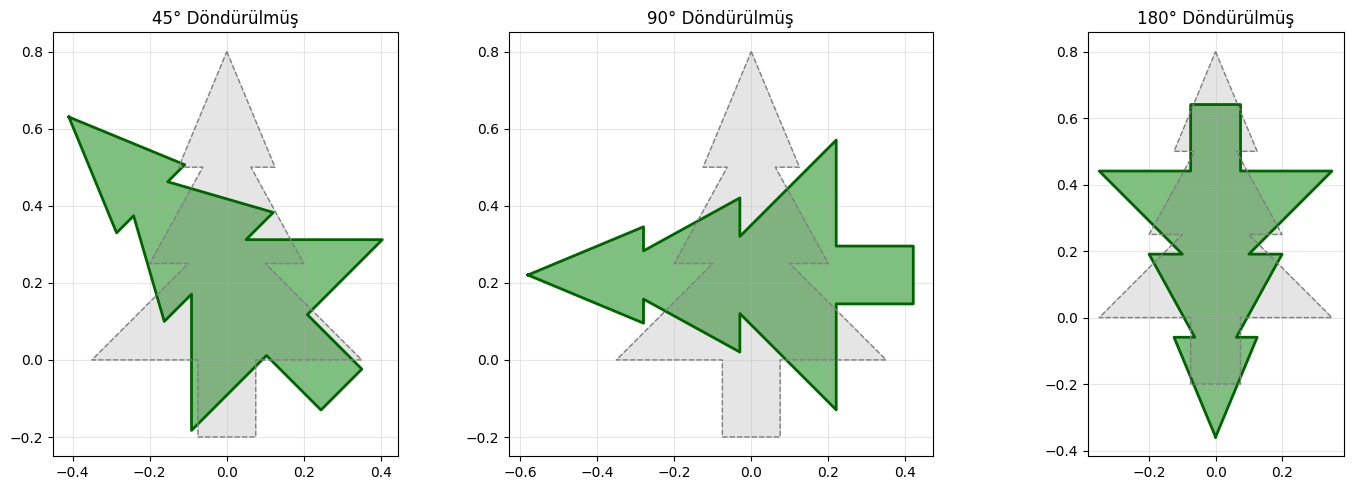

In [10]:
# Farklı açılarda döndürme örnekleri
orijinal = noel_agaci_olustur(0, 0)

# Merkez etrafında döndürme (derece cinsinden)
donmus_45 = affinity.rotate(orijinal, 45, origin='centroid')
donmus_90 = affinity.rotate(orijinal, 90, origin='centroid')
donmus_180 = affinity.rotate(orijinal, 180, origin='centroid')

# Orijin (0,0) etrafında döndürme
donmus_orijin = affinity.rotate(orijinal, 45, origin=(0, 0))

# Görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, geo, baslik in zip(axes, 
                            [donmus_45, donmus_90, donmus_180],
                            ['45° Döndürülmüş', '90° Döndürülmüş', '180° Döndürülmüş']):
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.5, color='green')
    ax.plot(x, y, color='darkgreen', linewidth=2)
    
    # Orijinali de göster
    ox, oy = orijinal.exterior.xy
    ax.fill(ox, oy, alpha=0.2, color='gray')
    ax.plot(ox, oy, color='gray', linewidth=1, linestyle='--')
    
    ax.set_aspect('equal')
    ax.set_title(baslik)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3 Scale (Ölçekleme)

In [11]:
# Ölçekleme örnekleri
orijinal = noel_agaci_olustur(0, 0)

# X ve Y yönünde eşit ölçekleme
buyuk = affinity.scale(orijinal, xfact=2, yfact=2, origin='centroid')
kucuk = affinity.scale(orijinal, xfact=0.5, yfact=0.5, origin='centroid')

# Asimetrik ölçekleme
genis = affinity.scale(orijinal, xfact=2, yfact=1, origin='centroid')

print(f"Orijinal Alan: {orijinal.area:.4f}")
print(f"Büyütülmüş Alan: {buyuk.area:.4f}")
print(f"Küçültülmüş Alan: {kucuk.area:.4f}")

Orijinal Alan: 0.2456
Büyütülmüş Alan: 0.9825
Küçültülmüş Alan: 0.0614


---
## 3️⃣ Çarpışma Algılama (Collision Detection) - 🎯 Yarışmanın Kalbi!

Noel ağaçlarının birbirine çarpmaması için kritik!

### 3.1 Temel Uzamsal İlişkiler

In [12]:
# İki çokgen oluştur
cokgen1 = box(0, 0, 3, 3)
cokgen2 = box(2, 2, 5, 5)  # Kesişiyor
cokgen3 = box(4, 0, 6, 2)  # Kesişmiyor
cokgen4 = box(3, 0, 4, 1)  # Dokunuyor

print("=== Kesişim Kontrolleri ===")
print(f"Çokgen1 ve Çokgen2 kesişiyor mu? {cokgen1.intersects(cokgen2)}")
print(f"Çokgen1 ve Çokgen3 kesişiyor mu? {cokgen1.intersects(cokgen3)}")
print(f"Çokgen1 ve Çokgen4 kesişiyor mu? {cokgen1.intersects(cokgen4)}")

print("\n=== Dokunma Kontrolleri ===")
print(f"Çokgen1 ve Çokgen2 dokunuyor mu? {cokgen1.touches(cokgen2)}")
print(f"Çokgen1 ve Çokgen4 dokunuyor mu? {cokgen1.touches(cokgen4)}")

=== Kesişim Kontrolleri ===
Çokgen1 ve Çokgen2 kesişiyor mu? True
Çokgen1 ve Çokgen3 kesişiyor mu? False
Çokgen1 ve Çokgen4 kesişiyor mu? True

=== Dokunma Kontrolleri ===
Çokgen1 ve Çokgen2 dokunuyor mu? False
Çokgen1 ve Çokgen4 dokunuyor mu? True


In [13]:
# 🎯 Yarışma için önemli: Çarpışma = Kesişiyor AMA Dokunmuyor
def carpisma_var_mi(geo1, geo2):
    """
    İki geometri arasında çarpışma olup olmadığını kontrol eder.
    Sadece dokunma durumu çarpışma sayılmaz!
    """
    return geo1.intersects(geo2) and not geo1.touches(geo2)

print(f"Çokgen1-Çokgen2 çarpışma: {carpisma_var_mi(cokgen1, cokgen2)}")
print(f"Çokgen1-Çokgen3 çarpışma: {carpisma_var_mi(cokgen1, cokgen3)}")
print(f"Çokgen1-Çokgen4 çarpışma: {carpisma_var_mi(cokgen1, cokgen4)}")

Çokgen1-Çokgen2 çarpışma: True
Çokgen1-Çokgen3 çarpışma: False
Çokgen1-Çokgen4 çarpışma: False


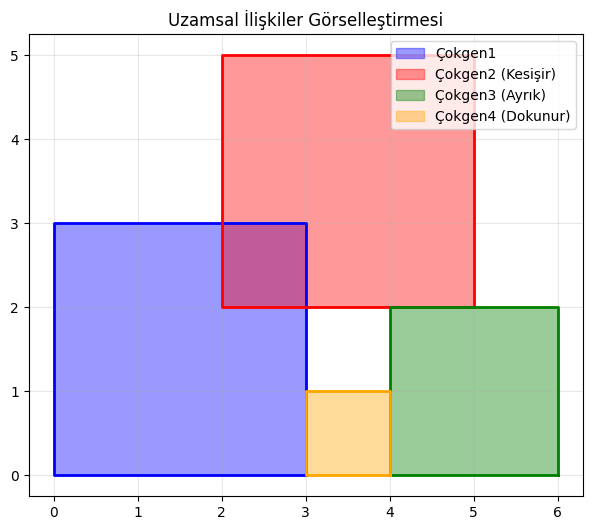

In [14]:
# Görselleştirme
fig, ax = plt.subplots(figsize=(10, 6))

cokgenler = [cokgen1, cokgen2, cokgen3, cokgen4]
renkler = ['blue', 'red', 'green', 'orange']
etiketler = ['Çokgen1', 'Çokgen2 (Kesişir)', 'Çokgen3 (Ayrık)', 'Çokgen4 (Dokunur)']

for geo, renk, etiket in zip(cokgenler, renkler, etiketler):
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.4, color=renk, label=etiket)
    ax.plot(x, y, color=renk, linewidth=2)

ax.set_aspect('equal')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_title('Uzamsal İlişkiler Görselleştirmesi')
plt.show()

### 3.2 Diğer Uzamsal İlişkiler

In [15]:
buyuk_kare = box(0, 0, 10, 10)
kucuk_kare = box(2, 2, 4, 4)
disardaki = box(12, 12, 15, 15)

print("=== Contains (İçeriyor mu?) ===")
print(f"Büyük kare küçük kareyi içeriyor mu? {buyuk_kare.contains(kucuk_kare)}")
print(f"Küçük kare büyük kareyi içeriyor mu? {kucuk_kare.contains(buyuk_kare)}")

print("\n=== Within (İçinde mi?) ===")
print(f"Küçük kare büyük karenin içinde mi? {kucuk_kare.within(buyuk_kare)}")

print("\n=== Disjoint (Ayrık mı?) ===")
print(f"Büyük kare ve dışardaki ayrık mı? {buyuk_kare.disjoint(disardaki)}")

print("\n=== Mesafe ===")
print(f"Büyük kare ile dışardaki arası mesafe: {buyuk_kare.distance(disardaki):.2f}")

=== Contains (İçeriyor mu?) ===
Büyük kare küçük kareyi içeriyor mu? True
Küçük kare büyük kareyi içeriyor mu? False

=== Within (İçinde mi?) ===
Küçük kare büyük karenin içinde mi? True

=== Disjoint (Ayrık mı?) ===
Büyük kare ve dışardaki ayrık mı? True

=== Mesafe ===
Büyük kare ile dışardaki arası mesafe: 2.83


---
## 4️⃣ STRtree - Hızlı Uzamsal Sorgular 🚀

Çok sayıda geometri ile çalışırken performans için kritik!

In [16]:
# Rastgele konumlarda birçok ağaç oluştur
np.random.seed(42)
agac_sayisi = 50

agaclar = []
for _ in range(agac_sayisi):
    x = np.random.uniform(-5, 5)
    y = np.random.uniform(-5, 5)
    aci = np.random.uniform(0, 360)
    
    agac = noel_agaci_olustur(0, 0, 0.3)
    agac = affinity.rotate(agac, aci, origin='centroid')
    agac = affinity.translate(agac, xoff=x, yoff=y)
    agaclar.append(agac)

print(f"Oluşturulan ağaç sayısı: {len(agaclar)}")

Oluşturulan ağaç sayısı: 50


In [17]:
# STRtree oluştur - bu veri yapısı sorguları çok hızlandırır!
agac_indeksi = STRtree(agaclar)

# Belirli bir bölgedeki ağaçları bul
sorgu_bolge = box(-2, -2, 2, 2)

# Query metodu ile potansiyel kesişimleri bul
aday_indeksler = agac_indeksi.query(sorgu_bolge)
print(f"Sorgu bölgesiyle potansiyel kesişim: {len(aday_indeksler)} ağaç")

# Gerçek kesişimleri kontrol et
gercek_kesisimler = [i for i in aday_indeksler 
                     if agaclar[i].intersects(sorgu_bolge)]
print(f"Gerçek kesişim: {len(gercek_kesisimler)} ağaç")

Sorgu bölgesiyle potansiyel kesişim: 10 ağaç
Gerçek kesişim: 10 ağaç


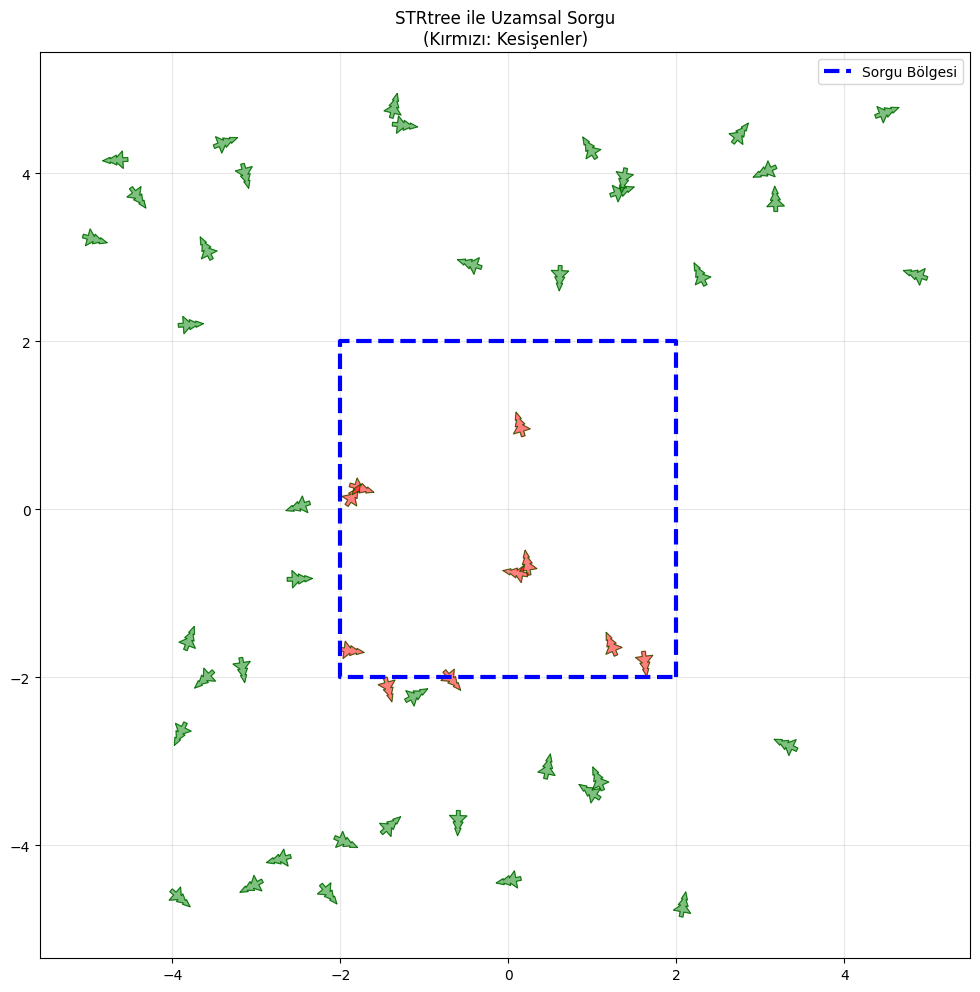

In [18]:
# Görselleştirme
fig, ax = plt.subplots(figsize=(12, 12))

# Tüm ağaçları çiz
for i, agac in enumerate(agaclar):
    x, y = agac.exterior.xy
    renk = 'red' if i in gercek_kesisimler else 'green'
    ax.fill(x, y, alpha=0.5, color=renk)
    ax.plot(x, y, color='darkgreen', linewidth=0.5)

# Sorgu bölgesini çiz
sx, sy = sorgu_bolge.exterior.xy
ax.plot(sx, sy, 'b--', linewidth=3, label='Sorgu Bölgesi')

ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_title('STRtree ile Uzamsal Sorgu\n(Kırmızı: Kesişenler)')
plt.show()

### 4.1 Performans Karşılaştırması

In [19]:
import time

# Daha fazla ağaç oluştur
np.random.seed(123)
cok_agac = []
for _ in range(500):
    x = np.random.uniform(-20, 20)
    y = np.random.uniform(-20, 20)
    agac = noel_agaci_olustur(0, 0, 0.2)
    agac = affinity.translate(agac, xoff=x, yoff=y)
    cok_agac.append(agac)

# Yeni bir ağaç eklemek istiyoruz - çarpışma kontrolü
yeni_agac = noel_agaci_olustur(0, 0, 0.3)

# Yöntem 1: Naif yaklaşım (tüm ağaçları kontrol et)
baslangic = time.time()
naif_sonuc = []
for i, agac in enumerate(cok_agac):
    if carpisma_var_mi(yeni_agac, agac):
        naif_sonuc.append(i)
naif_sure = time.time() - baslangic
print(f"Naif yöntem: {naif_sure*1000:.2f} ms, {len(naif_sonuc)} çarpışma")

# Yöntem 2: STRtree kullan
baslangic = time.time()
agac_index = STRtree(cok_agac)
adaylar = agac_index.query(yeni_agac)
strtree_sonuc = [i for i in adaylar if carpisma_var_mi(yeni_agac, cok_agac[i])]
strtree_sure = time.time() - baslangic
print(f"STRtree yöntemi: {strtree_sure*1000:.2f} ms, {len(strtree_sonuc)} çarpışma")

print(f"\nHızlanma: {naif_sure/strtree_sure:.1f}x")

Naif yöntem: 0.74 ms, 0 çarpışma
STRtree yöntemi: 0.17 ms, 0 çarpışma

Hızlanma: 4.3x


---
## 5️⃣ Geometri İşlemleri (Set Operations)

In [20]:
a = box(0, 0, 3, 3)
b = box(1, 1, 4, 4)

# Birleşim (Union)
birlesim = a.union(b)

# Kesişim (Intersection)
kesisim = a.intersection(b)

# Fark (Difference)
fark = a.difference(b)

# Simetrik Fark
simetrik_fark = a.symmetric_difference(b)

print(f"A Alanı: {a.area}")
print(f"B Alanı: {b.area}")
print(f"Birleşim Alanı: {birlesim.area}")
print(f"Kesişim Alanı: {kesisim.area}")
print(f"Fark Alanı: {fark.area}")

A Alanı: 9.0
B Alanı: 9.0
Birleşim Alanı: 14.0
Kesişim Alanı: 4.0
Fark Alanı: 5.0


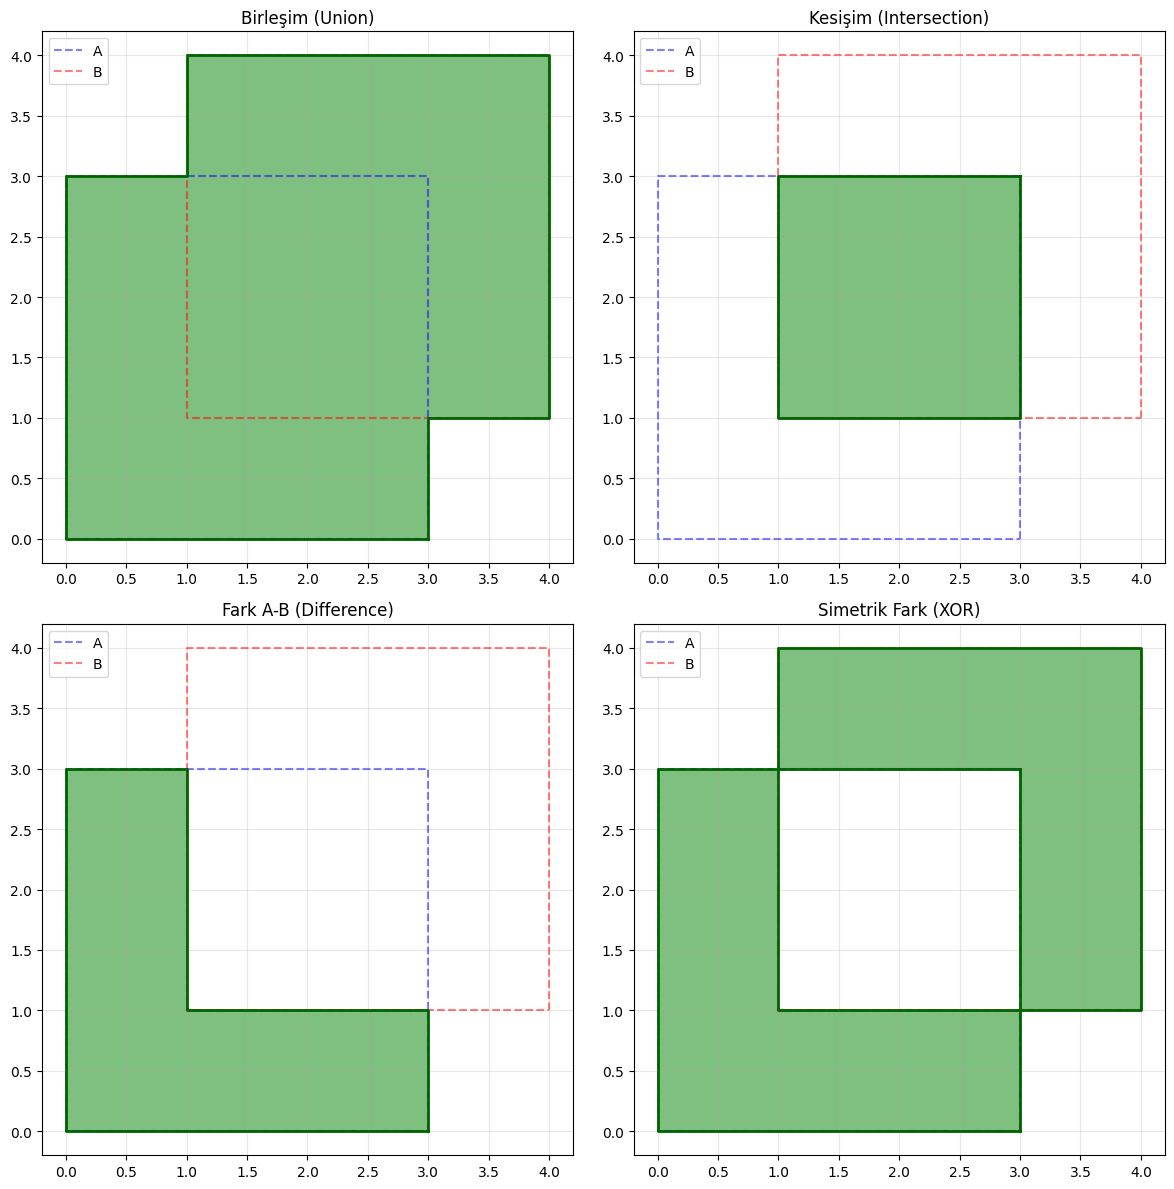

In [21]:
# Görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

islemler = [
    (birlesim, 'Birleşim (Union)'),
    (kesisim, 'Kesişim (Intersection)'),
    (fark, 'Fark A-B (Difference)'),
    (simetrik_fark, 'Simetrik Fark (XOR)')
]

for ax, (geo, baslik) in zip(axes.flat, islemler):
    # A ve B'yi arka planda göster
    ax_, ay_ = a.exterior.xy
    bx_, by_ = b.exterior.xy
    ax.plot(ax_, ay_, 'b--', alpha=0.5, label='A')
    ax.plot(bx_, by_, 'r--', alpha=0.5, label='B')
    
    # Sonucu göster
    if hasattr(geo, 'exterior'):
        x, y = geo.exterior.xy
        ax.fill(x, y, alpha=0.5, color='green')
        ax.plot(x, y, color='darkgreen', linewidth=2)
    elif hasattr(geo, 'geoms'):
        for g in geo.geoms:
            x, y = g.exterior.xy
            ax.fill(x, y, alpha=0.5, color='green')
            ax.plot(x, y, color='darkgreen', linewidth=2)
    
    ax.set_aspect('equal')
    ax.set_title(baslik)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.1 Unary Union - Birden Fazla Geometriyi Birleştirme

In [22]:
from shapely.ops import unary_union

# Birden fazla kutu oluştur
kutular = [box(i, i, i+2, i+2) for i in range(5)]

# Hepsini birleştir
birlesik = unary_union(kutular)

# Bounds (sınır kutusu) hesapla - yarışma için önemli!
sinirlar = birlesik.bounds
print(f"Sınır Kutusu: {sinirlar}")
print(f"Genişlik: {sinirlar[2] - sinirlar[0]}")
print(f"Yükseklik: {sinirlar[3] - sinirlar[1]}")
print(f"Maximum kenar: {max(sinirlar[2] - sinirlar[0], sinirlar[3] - sinirlar[1])}")

Sınır Kutusu: (0.0, 0.0, 6.0, 6.0)
Genişlik: 6.0
Yükseklik: 6.0
Maximum kenar: 6.0


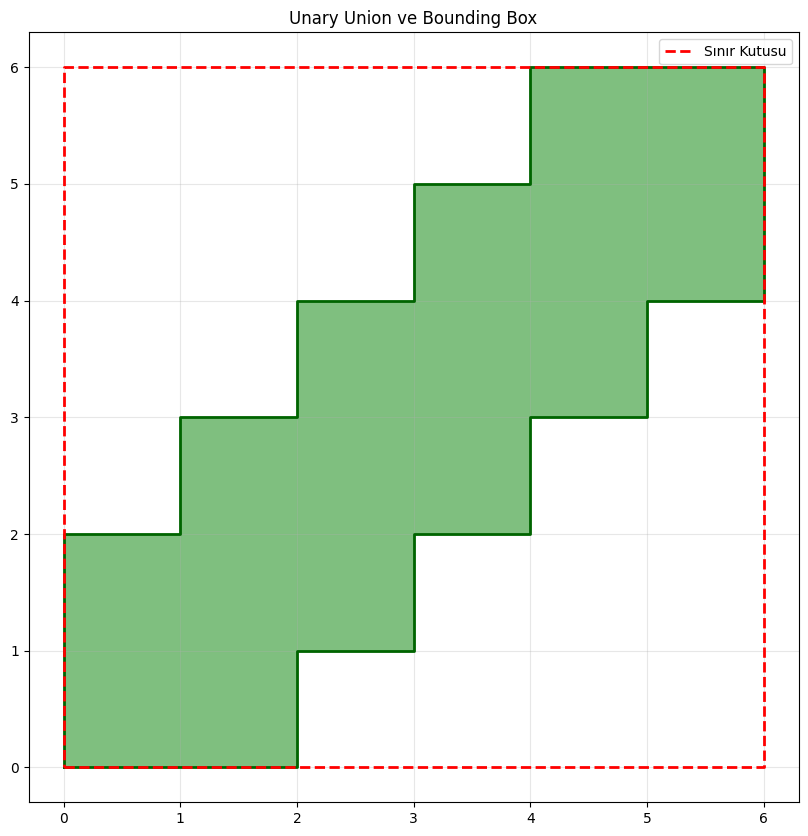

In [23]:
# Görselleştirme
fig, ax = plt.subplots(figsize=(10, 10))

# Birleştirilmiş geometriyi çiz
if hasattr(birlesik, 'exterior'):
    x, y = birlesik.exterior.xy
    ax.fill(x, y, alpha=0.5, color='green')
    ax.plot(x, y, color='darkgreen', linewidth=2)
elif hasattr(birlesik, 'geoms'):
    for g in birlesik.geoms:
        x, y = g.exterior.xy
        ax.fill(x, y, alpha=0.5, color='green')
        ax.plot(x, y, color='darkgreen', linewidth=2)

# Sınır kutusunu çiz
minx, miny, maxx, maxy = sinirlar
ax.plot([minx, maxx, maxx, minx, minx], 
        [miny, miny, maxy, maxy, miny], 
        'r--', linewidth=2, label='Sınır Kutusu')

ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_title('Unary Union ve Bounding Box')
plt.show()

---
## 6️⃣ Buffer ve Simplify

In [24]:
# Buffer - geometriyi genişletme/daraltma
orijinal = noel_agaci_olustur(0, 0)

# Pozitif buffer (genişletme)
genisletilmis = orijinal.buffer(0.1)

# Negatif buffer (daraltma)
daraltilmis = orijinal.buffer(-0.05)

print(f"Orijinal Alan: {orijinal.area:.4f}")
print(f"Genişletilmiş Alan: {genisletilmis.area:.4f}")
print(f"Daraltılmış Alan: {daraltilmis.area:.4f}")

Orijinal Alan: 0.2456
Genişletilmiş Alan: 0.5788
Daraltılmış Alan: 0.1020


In [25]:
# Simplify - geometriyi basitleştirme
# Çok noktadan oluşan karmaşık geometrileri basitleştirmek için kullanışlı

# Karmaşık bir geometri oluştur (genişletilmiş ağaç)
karmasik = orijinal.buffer(0.1)
basitlestirilmis = karmasik.simplify(tolerance=0.05)

print(f"Karmaşık geometri nokta sayısı: {len(karmasik.exterior.coords)}")
print(f"Basitleştirilmiş geometri nokta sayısı: {len(basitlestirilmis.exterior.coords)}")

Karmaşık geometri nokta sayısı: 160
Basitleştirilmiş geometri nokta sayısı: 10


---
## 7️⃣ Yarışma Simülasyonu: Ağaç Yerleştirme Algoritması

In [26]:
def agac_yerlestir(mevcut_agaclar, yeni_agac):
    """
    Yeni bir ağacı çarpışma olmadan yerleştirmeye çalışır.
    Yarışmadaki algoritmanın basitleştirilmiş versiyonu.
    """
    if not mevcut_agaclar:
        return yeni_agac, True
    
    # STRtree ile hızlı arama
    agac_index = STRtree(mevcut_agaclar)
    adaylar = agac_index.query(yeni_agac)
    
    # Çarpışma kontrolü
    for i in adaylar:
        if carpisma_var_mi(yeni_agac, mevcut_agaclar[i]):
            return None, False
    
    return yeni_agac, True


def greedy_yerlestirme(n_agac, sinir=5):
    """
    Açgözlü (greedy) yaklaşımla ağaç yerleştirme.
    Her ağacı merkeze en yakın çarpışmasız konuma yerleştirir.
    """
    yerlestirilmis = []
    
    for i in range(n_agac):
        en_iyi_konum = None
        en_kucuk_mesafe = float('inf')
        
        # Farklı açılar dene
        for aci in np.linspace(0, 360, 36, endpoint=False):
            # Farklı mesafeler dene
            for mesafe in np.linspace(0, sinir, 50):
                x = mesafe * np.cos(np.radians(aci))
                y = mesafe * np.sin(np.radians(aci))
                
                yeni = noel_agaci_olustur(0, 0, 0.3)
                yeni = affinity.rotate(yeni, np.random.uniform(0, 360), origin='centroid')
                yeni = affinity.translate(yeni, xoff=x, yoff=y)
                
                yerlesik, basarili = agac_yerlestir(yerlestirilmis, yeni)
                
                if basarili and mesafe < en_kucuk_mesafe:
                    en_kucuk_mesafe = mesafe
                    en_iyi_konum = yeni
        
        if en_iyi_konum is not None:
            yerlestirilmis.append(en_iyi_konum)
    
    return yerlestirilmis


# 10 ağaç yerleştir
sonuc_agaclar = greedy_yerlestirme(10)
print(f"Başarıyla yerleştirilen ağaç sayısı: {len(sonuc_agaclar)}")

Başarıyla yerleştirilen ağaç sayısı: 10


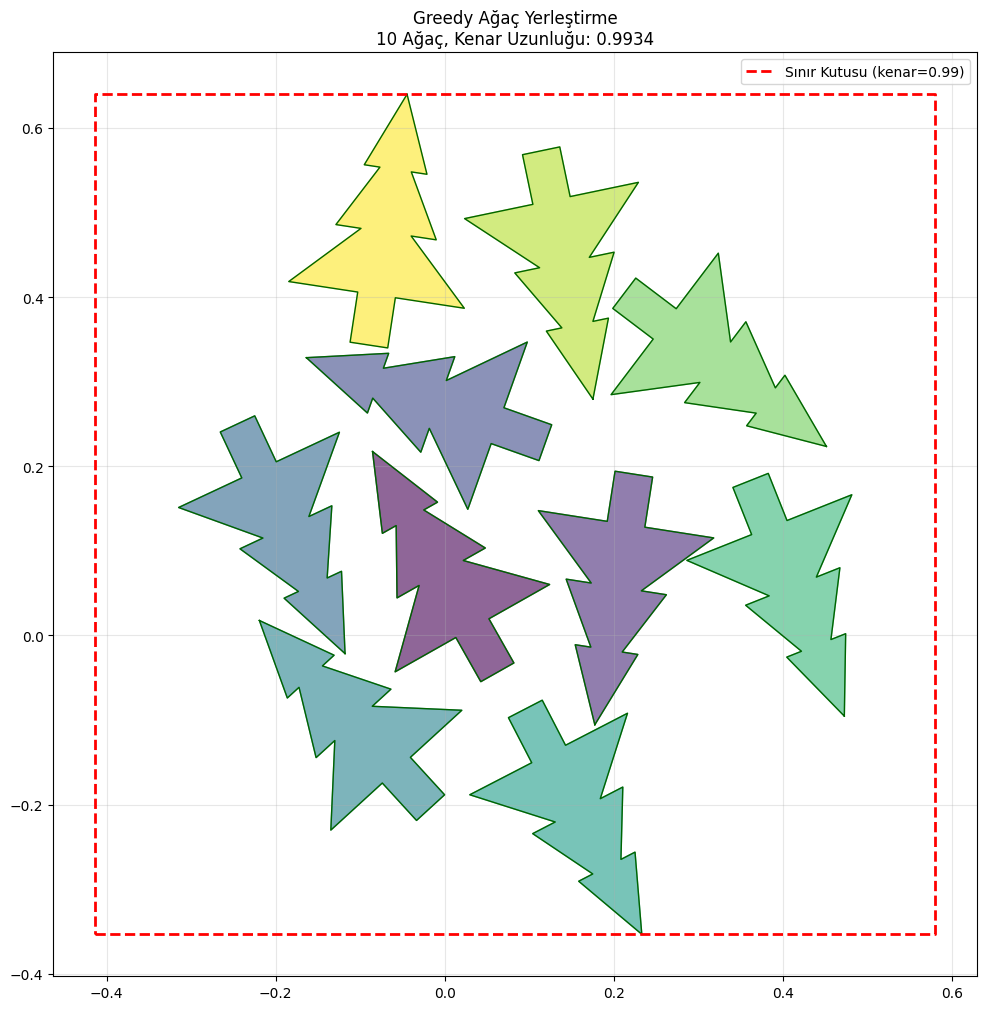

In [27]:
# Sonucu görselleştir
fig, ax = plt.subplots(figsize=(12, 12))

# Ağaçları çiz
renkler = plt.cm.viridis(np.linspace(0, 1, len(sonuc_agaclar)))
for agac, renk in zip(sonuc_agaclar, renkler):
    x, y = agac.exterior.xy
    ax.fill(x, y, alpha=0.6, color=renk)
    ax.plot(x, y, color='darkgreen', linewidth=1)

# Sınır kutusunu hesapla ve çiz
all_union = unary_union(sonuc_agaclar)
minx, miny, maxx, maxy = all_union.bounds
kenar = max(maxx - minx, maxy - miny)

# Kare sınır kutusu
merkez_x = (minx + maxx) / 2
merkez_y = (miny + maxy) / 2
kare_min_x = merkez_x - kenar / 2
kare_min_y = merkez_y - kenar / 2

ax.plot([kare_min_x, kare_min_x + kenar, kare_min_x + kenar, kare_min_x, kare_min_x],
        [kare_min_y, kare_min_y, kare_min_y + kenar, kare_min_y + kenar, kare_min_y],
        'r--', linewidth=2, label=f'Sınır Kutusu (kenar={kenar:.2f})')

ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_title(f'Greedy Ağaç Yerleştirme\n{len(sonuc_agaclar)} Ağaç, Kenar Uzunluğu: {kenar:.4f}')
plt.show()

---
## 8️⃣ Yarışma İçin Özet ve İpuçları

### Önemli Shapely Fonksiyonları:

| Fonksiyon | Açıklama | Yarışmadaki Kullanım |
|-----------|----------|---------------------|
| `Polygon()` | Çokgen oluşturma | Noel ağacı şekli tanımlama |
| `affinity.translate()` | Öteleme | Ağacı konumlandırma |
| `affinity.rotate()` | Döndürme | Ağacı döndürme |
| `intersects()` | Kesişim kontrolü | Çarpışma tespiti |
| `touches()` | Dokunma kontrolü | Geçerli yerleşim tespiti |
| `STRtree()` | Uzamsal indeks | Performans optimizasyonu |
| `unary_union()` | Birleştirme | Toplam sınır kutusu hesaplama |
| `.bounds` | Sınır kutusu | Skor hesaplama |

### Performans İpuçları:
1. ✅ Büyük veri setlerinde mutlaka `STRtree` kullanın
2. ✅ Önce `intersects()`, sonra `touches()` kontrolü yapın
3. ✅ Yüksek hassasiyet için `Decimal` kullanın (yarışma örneğindeki gibi)
4. ✅ `bounds` ile hızlıca sınır kutusu hesaplayın

### Yarışma Stratejisi:
1. Ağaçları merkeze yakın yerleştirin
2. Döndürme açılarını optimize edin
3. Köşelere ağaç yerleştirmek için açıları iyileştirin
4. Greedy sonuçlarını yerel arama ile iyileştirin

In [28]:
print("🎄 Shapely Tutorial Tamamlandı! 🎄")
print("\nBaşarılar dilerim!")

🎄 Shapely Tutorial Tamamlandı! 🎄

Başarılar dilerim!
